---

# Introduction to Data Science and Systems 2026-2027

## Week 7: Probability II
\- Probability theory, Bayes' Rule, discrete and continuous random variables

##### University of Glasgow - material prepared by John H. Williamson (adapted to IDSS by NP/BSJ), <small>v20262027a</small>

----

# Summary
By the end of this unit you should know:

* conditional, marginal and joint distribution
* what entropy is and how it can be computed
* Bayes' rule and how to apply it problems
* what bigrams are and how they can be used


In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from jhwutils.float_inspector import print_shape_html, print_float, print_float_html
from jhwutils.matrices import show_boxed_tensor_latex, print_matrix
import jhwutils.image_audio as ia
import numpy as np
%matplotlib inline
plt.rc('figure', figsize=(8.0, 4.0), dpi=140)

def discrete_sample(pmf, n):
    keys = list(pmf.keys())    
    # cumulative mass function
    cmf = np.cumsum(list(pmf.values()))
    
    # generate n random values, between 0 and 1
    samples = np.random.uniform(0, 1, n)

    # code the values according to the bins
    return [keys[i] for i in np.digitize(samples, cmf)]

In [2]:
%%latex
\renewcommand{\vec}[1]{{\bf #1} } 
\newenvironment{examinable}{}{{\ \ [\spadesuit]}}
\newcommand{\real}{\mathbb{R}}
\newcommand{\expect}[1]{\mathbb{E}[#1]}
\newcommand{\argmin}{\operatorname*{arg\,min}}

<IPython.core.display.Latex object>

## Last week: Romeo & Juliet by the letters
The following code loads a text file (in this case, *Romeo and Juliet*), and converts into a vector of numerical codes. It keeps only letters and space, and converts everything to lowercase.

> Rom.  Give me a torch. I am not for this ambling.  
        Being but heavy, I will bear the light.  
>     
> Mer. Nay, gentle Romeo, we must have you dance.  
>  
> Rom.  Not I, believe me. You have dancing shoes  
        With nimble soles; I have a soul of lead  
        So stakes me to the ground I cannot move.  
>            
   

In [3]:
alphabet = 'abcdefghijklmnopqrstuvwxyz '
#alphabet = ' eaoiutnshrdlcmfwypvbgkjqxz'

def numerify(fname):    
    with open(fname) as f:        
        return np.array([alphabet.index(c) for c in f.read().lower() if c in alphabet])    

We can compute the empirical distribution of letters in Romeo and Juliet. Its probability mass function is just given by the normalised count of each character.

In [4]:
def empirical_pmf_plot(vector, alphabet, title):
    fig = plt.figure()
    ax = fig.add_subplot(1,1,1)
    probs,_,_ = ax.hist(vector, bins=np.arange(len(alphabet)+1), density=True)
    
    ax.set_xticks(np.arange(len(alphabet))+0.5)
    ax.set_xticklabels(alphabet)
    ax.set_xlabel("Character $x$")
    ax.set_ylabel("Empirical probability $P(X=x)$")
    ax.set_title("Empirical PMF of {0}".format(title))
    return probs

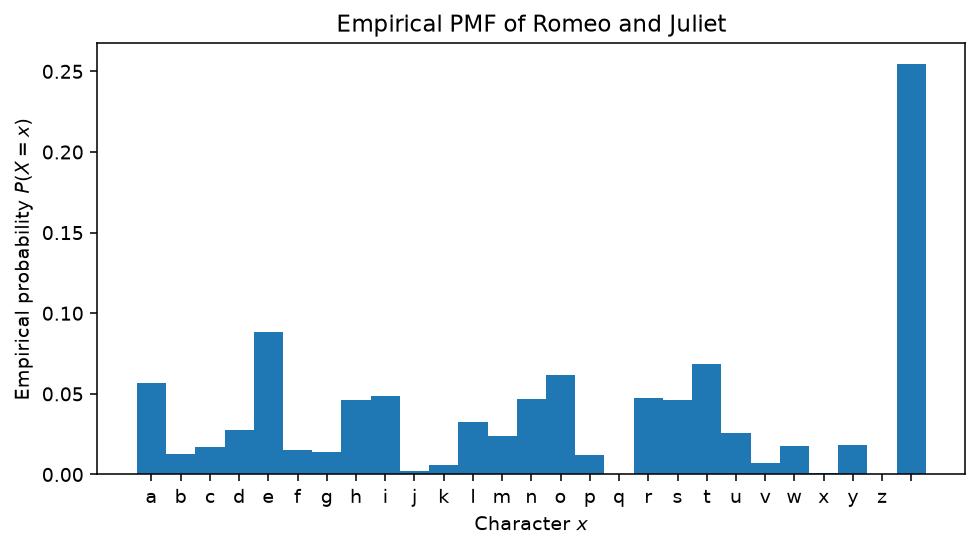

In [5]:
rj_chars = numerify("data/romeo_juliet.txt")
rj_pmf = empirical_pmf_plot(rj_chars, alphabet, "Romeo and Juliet")    
plt.show()

### Kafka
We can repeat the process with Kafka's *Metamorphosis*; an English text, but one with a different writing style.

> "What's happened to me?" he thought.  It wasn't a dream.  His room, a proper human room although a little too small, lay peacefully between its four familiar walls.  A collection of textile samples lay spread out on the table - Samsa was a travelling salesman - and above it there hung a picture that he had recently cut out of an illustrated magazine and housed in a nice, gilded frame.  It showed a lady fitted out with a fur hat and fur boa who sat upright, raising a heavy fur muff that covered the whole of her lower arm towards the viewer.

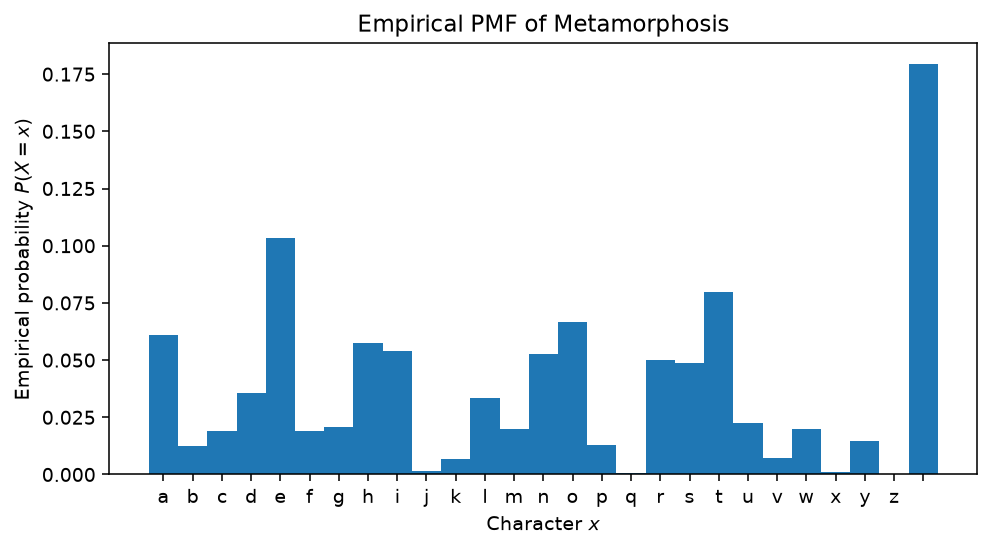

In [6]:
metamorphosis = numerify("data/metamorphosis.txt")
metamorphosis_pmf = empirical_pmf_plot(metamorphosis, alphabet, "Metamorphosis")    
plt.show()

The results are similar (both are English texts), but there are some subtle differences; there slightly more `q` characters in Kafka compared to Shakespeare; the frequencies of `h` and `i` are reversed.



As always, given a PMF, we can draw samples from it with our standard procedure, though the results aren't very exciting:

In [7]:
dict_pmf = {outcome:p for outcome,p in zip(alphabet, rj_pmf)}
"".join(discrete_sample(dict_pmf, 140))

'da ltinm laph nagdas e  sis   bch shrluittto llct vmr e ir e adt lsn b arsbe  swrdo  ron  w eet mee  wece  ittntaeh ceg ohfhabenoi algeea tb'

In [8]:
dict_pmf = {outcome:p for outcome,p in zip(alphabet, rj_pmf)}
"".join(discrete_sample(dict_pmf, 140))

' tna g    yescott nc n uvn ohs n pi  au ts dadovrosnudtes is tsohpe ss  u ihi rs th nlsu mmrnclnaluuergeoeu iset eslts hncth gt re eahngavfu'

----

## Likelihood to compare 

For example, consider the empirical PMF of Romeo and Juliet. This gives the probability of seeing any given character. The likelihood of seeing **all of the characters**, given our per-character probability model, is:

$$\mathcal{L}(c_1, c_2, \dots\ c_n) = \prod_i P(c_i)$$

This is the likelihood of the text given our model. 

In [9]:
def likelihood(sequence, p):
    
    result = 1.0
    for char in sequence:
        # this is bad: multiplying lots of small numbers
        # will underflow very quickly
        result = result * p[char]
    return result
    

In practice, we use the log-likelihood to avoid underflow issues:
    
$$\log \mathcal{L}(c_1, c_2, \dots\ c_n) = \sum_i \log P(c_i)$$


In [10]:
def log_likelihood(sequence, p):
    result = 0.0
    for char in sequence:
        ## summing logs is stable numerically
        result = result + np.log(p[char])
    return result


In [11]:
print(likelihood(rj_chars, rj_pmf)) # huh?

0.0


In [12]:
# 
print(log_likelihood(rj_chars, rj_pmf))

-435054.17532227805


## Comparing log-likelihoods
We could imagine that writing plays and novels is an activity that mysterious entities do by generating random characters according to a PMF. Under this (very simplified!) assumption, we could now take an "unknown" text (in this case *Macbeth*) and then look at how likely it would have been to have been generated under two models:
* *A* It was generated by a mysterious entity using the PMF for *Romeo and Juliet*
* *B* It was generated by a mysterious entity using the PMF for *Metamorphosis*

Neither of these will be exactly true, but we can precisely quantify to what extent *Macbeth* appears to have been generated by a similar process to these two reference texts.

This is a very rough proxy for whether or not they were generated by the same mysterious entity -- i.e. author. Our model is just the distribution of characters, so is a fairly weak model of different styles. However, it is sufficient to do the comparison here.

In [13]:
macbeth_chars = numerify("data/macbeth.txt")

## A positive value indicates more likely to be "like" 
# Romeo and Juliet; negative is evidence
## in favour of Metamorphosis (i.e. written by Kafka)
print(log_likelihood(macbeth_chars, rj_pmf)-
      log_likelihood(macbeth_chars, metamorphosis_pmf))

2108.0159321859246


In [14]:
## We could repeat this with another text, in this case
## "The Trial", by Kafka
trial_chars = numerify("data/the_trial.txt")

## A positive value indicates more likely to be "like" Romeo and Juliet
print(log_likelihood(trial_chars , rj_pmf)-
      log_likelihood(trial_chars, metamorphosis_pmf))

-6191.640841528075


### Joint, conditional, marginal

The **joint probability** of two random variables is written $$P(X,Y)$$ and gives the probability that $X$ and $Y$ take the specific values *simultaneously* (i.e. $P(X=x) \land P(Y=y)$). 

The **marginal probability** is the derivation of $P(X)$ from $P(X,Y)$ by integrating (summing) over all the possible outcomes of $Y$:
<div class="alert alert-box alert-success">
$$P(X) = \int_y P(X,Y) dy\  \text{for a PDF.}$$
$$P(X) = \sum_y P(X,Y)\  \text{for a PMF.}$$
    </div>

This allows us to compute a distribution over one random variable from a joint distribution by summing over all the possible outcomes of the other variable involved.

**Marginalisation** just means integration over one or more variables from a joint distribution: it *removes* those variables from the distribution.

Two random variables are **independent** if the they do not have any dependence on each other. If this is the case then the joint distribution is just the product of the individual distributions: $P(X,Y) = P(X)P(Y).$ This is **not true in the general case where the variables have dependence**.

The **conditional probability** of a random variable $X$ *given* a random variable $Y$ is written as $$P(X|Y)$$ and can be computed as
<div class="alert alert-box alert-success"> 

$$P(X|Y) = \frac{P(X,Y)}{P(Y)}. $$ </div>

This tells us how likely the outcomes of $X$ are *if we already know* (or fix) the outcomes of $Y$. Read as "probability of X taking on the value x given that Y has taken on the value y". The conditional probability is $P(X|Y)=P(X)$ and $P(Y|X)=P(Y)$ if $X$ and $Y$ are independent.

## Bigrams
We can look at these in the case of the character model of text we saw earlier. From the vector of character codes that make up "Metamorphosis" we can take every *pair of characters*, in order that they appear. That is, we consider two characters $c_{i-1}$ and $c_i$ at some index $i$. This is called a **bigram** model, and there are unigram, trigram, n-gram generalisations of the idea. A "gram" refers to a unit like a character or word, and we are discussing a character **bigram model**.


* The joint distribution of bigrams $P(C_i=c_i, C_{i-1}=c_{i-1})$ is given by the normalized count of each character pair.

* The marginal distribution $P(C_i=c_i)$ can be computed from $P(C_i=c_i, C_{i-1}=c_{i-1})$ by summing over every possible character $c_{i-1}$, and likewise to marginalise to find $P(C_{i-1}=c_{i-1})$

* The conditional distribution $P(C_i=c_i|C_{i-1}=c_{i-1})$ is given by the joint distribution, divided by the counts of $P(C_{i-1}=c_{i-1})$. It tells us how likely we are to observe a specific character $c_i$ *given* that we have observed a character $c_{i-1}$ just beforehand.



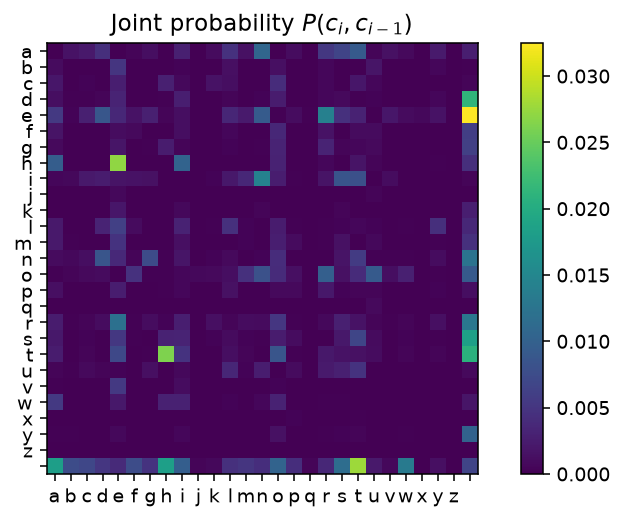

In [15]:
meta_joint = np.zeros([len(alphabet), len(alphabet)])
for c_1, c_2 in zip(metamorphosis[1:], metamorphosis[:-1]):
    meta_joint[c_2, c_1] += 1

# normalise by total number of pairs
meta_joint = meta_joint / np.sum(meta_joint)   

def show_2d_histogram(hist):
    fig = plt.figure()
    ax = fig.add_subplot(1,1,1)
    img = ax.imshow(hist)
    fig.colorbar(img)
    ax.set_xticks(np.arange(len(alphabet)))
    ax.set_xticklabels(alphabet)
    ax.set_yticks(np.arange(len(alphabet)))
    ax.set_yticklabels(alphabet)
    ax.set_title("Joint probability $P(c_{i},c_{i-1})$")

# rows = c_i-1, columns = c_i    
show_2d_histogram(meta_joint)
plt.show()

This tells us how likely each possible **pair** of characters is. Some combinations are much more likely than others.

In [16]:
# compute the marginial probabilities, by summing over the relevant axes
# it's this easy!
meta_c1 = np.sum(meta_joint, axis=0)
meta_c2 = np.sum(meta_joint, axis=1)

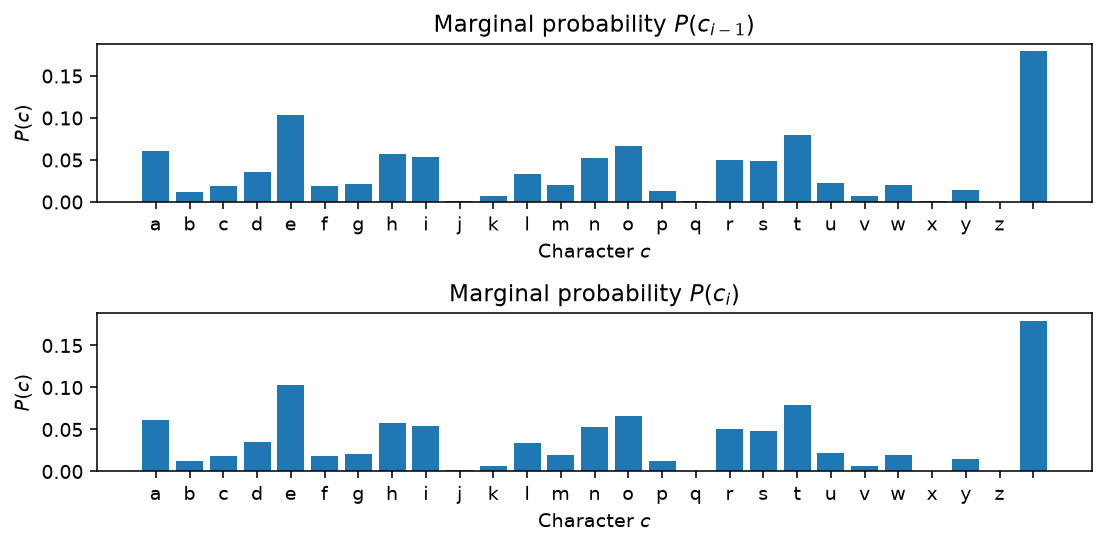

In [17]:
# plot them
fig = plt.figure()

def show_1d_histogram(hist):
    ax.bar(np.arange(len(alphabet)), hist)
    ax.set_xticks(np.arange(len(alphabet)))
    ax.set_xticklabels(alphabet)
    ax.set_ylabel("$P(c)$")
    ax.set_xlabel("Character $c$")

ax = fig.add_subplot(2,1,1)
show_1d_histogram(meta_c1)
ax.set_title("Marginal probability $P(c_{i-1})$")

ax = fig.add_subplot(2,1,2)
show_1d_histogram(meta_c2)
ax.set_title("Marginal probability $P(c_{i})$")
plt.tight_layout()
plt.show()

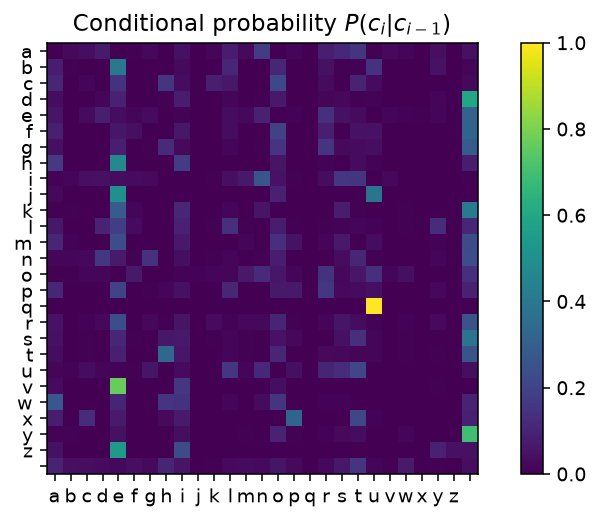

In [18]:
# p(c2|c1) = p(c1,x2) / p(c1)
# have to transpose to normalise across columns, instead of rows
meta_conditional = (meta_joint.T / meta_c1).T

# plot it
show_2d_histogram(meta_conditional)
plt.gca().set_title("Conditional probability $P(c_i|c_{i-1})$")
plt.show()

This tells us what character to expect, *given the character we know we saw before*. It lets us *predict* the next character. We can look along the rows to do this look up: each row sums to 1.0. For example, look at row "q": the probability is concentrated on the entry in column "u" -- "u" always follows "q" in English.

----

## ☣ Plague ☣

* A new test is developed that can detect *Plague X* with 95% accuracy. 
* We'll assume that 95% accuracy means:
    * a 5% **false positive rate**, i.e. 5% of the time people who don't have the disease test positive
    * a 5% **false negative rate**, i.e. 5% of the time people have the disease test negative
* One in one hundred thousand (1:100000) people are known to have *Plague X*
    * we might know this because it's universally fatal within one year, and one in a hundred thousand people died of it last year, for example.
* You go for the test, and it comes back *positive* for *Plague X*.
* How likely are you to have *Plague X*?

### Options
* A: about 95 in 100
* B: about  5 in 100
* C: about 1 in 100
* D: about 1 in 5000
* E: about 1 in 10000                              
        

# Bayes' Rule

## Prior, likelihood, posterior

### Inverting conditional distributions
We often want to know the probability of a some event $A$ given some other event $B$; that is $P(A|B)$. But we are often in the situation that we can only compute $P(B|A)$. 

This case is usually:
* we know how the mysterious entity behaves $P(B|A)$;
* we know what data we saw $P(B)$;
* we know what the mysterious entity is likely to be up to in general $P(A)$;
* and we want to work out what the mysterious entity is doing $P(A|B)$.

In general $P(A|B) \neq P(B|A);$ and the two expressions can be completely different. 

Typically, this type of problem occurs where we:
* want to know the probability of some event given some *evidence* (*how likely is it that I have a disease given that my blood test came back positive?*) 
* but we only know the probability of observing evidence given the event (*if you have this disease, the blood test will come back positive 95% of the time*).

**Bayes' rule** gives the correct way to invert the probability distribution:
<div class="alert alert-box alert-success">
    
$$ P(A|B) = \frac{P(B|A) P(A)}{P(B)} $$
</div>

This follows directly from the axioms of probability. Bayes' Rule is a very important rule, and has some surprising consequences. 

### Nomenclature
* $P(A|B)$ is called the **posterior** -- what we want to know, or will know after the computation
* $P(B|A)$ is called the **likelihood** -- how likely the event $A$ is to produce the evidence we see
* $P(A)$ is the **prior**  -- how likely the event $A$ is regardless of evidence
* $P(B)$ is the **evidence** -- how likely the evidence $B$ is regardless of the event.

Bayes' rule gives a consistent rule to take some prior belief and combine it with observed data to estimate a new distribution which combines them.

We often phrase this as some **hypothesis** $H$ we want to know, given some **data** $D$ we observe, and we write Bayes' Rule as:
<div class="alert alert-box alert-success">
    
$$ P(H|D) = \frac{P(D|H) P(H)}{P(D)} $$
</div>

$H$ and $D$ are random variables in this expression.

(the probability of the hypothesis given the data) is equal to (the probability of the data given the hypothesis) times (the probability of the hypothesis) divided by (the probability of the data). In other words, if we want to work out how likely a hypothesis is to be true given observations, but we only know how likely we are to have seen those observations if that hypothesis *was* true, we can use Bayes' rule to solve the problem.

## Integration over the evidence
We can say that the posterior probability is *proportional* to the product of the prior and the likelihood. But to evaluate its value, we need to compute $P(D)$, **the evidence**. 

It is difficult to see what this represents at first. But one way to think of it is as the result of marginalising the $P(D)$ from the joint distribution $P(H,D)$; that is integrating $P(H,D)$ over every possible outcome of $H$, for each possible $D$. 

<div class="alert alert-box alert-success">
Because probabilities must add up to 1, we can write $P(D)$ as:
$$P(D)  = \sum_{i} P(D|H_i) P(H_i) $$ 
for a set of discrete outcomes  $H_i$ or
$$ P(D) = \int_{H} P(D|H) P(H) dH $$ for a continuous distribution of outcomes.
</div>

<font color="green"> This trick is essential in understanding Bayes Rule! </font>

In general this can be difficult to compute. For binary simple cases where there are only two possible outcomes ($H$ can only be 0 or 1), Bayes' rule can be written as:

$$P(H=1|D) = \frac{P(D|H=1)P(H=1)}{P(D|H=1)P(H=1) + P(D|H=0) P(H=0)}, $$


  
    

Bayes Rule for *Plague X*

        P(Plague|Test) = [P(Test|Plague) P(Plague)] / P(Test)

        # integrate over the two possible 
        #states of Plague
        P(Test) =  [P(Test|not Plague)P(not Plague) +
                    P(Test|Plague)P(Plague)]
        

In [19]:
# one in a ten thousand have the plague
P_Plague = 1.0 / 100000    

# if you have the plague, test is positive with 5% error
P_Test_Plague = 1-0.05            
# If you don't have the plague, the test is positive 5% of the time
P_Test_not_Plague = 0.05        

# chance you don't have the plague, before we see the test
P_not_Plague = 1-P_Plague         

# integrate over evidence; only two possibilities here
P_Test = (P_Test_Plague * P_Plague +  
            P_Test_not_Plague * P_not_Plague)

# what is the probability you have the plague, 
# given this 95% accurate test?
# (hint: it is not 95%!)
P_Plague_Test = P_Test_Plague * P_Plague / P_Test

print("After testing positive, you have a 1:%.0f chance of having the plague" % ((1-P_Plague_Test)/P_Plague_Test))

After testing positive, you have a 1:5263 chance of having the plague


## Natural frequency
There is an approach to explaining problems like this which makes it much less likely to make poor judgements. **Natural frequency** explanations involve imagining concrete populations of a fixed size (10000 people in a room, for example), and considering the proportions of the populations as *counts* (how many people in the room have the plague?).

We can use this to visualise the problem above and explain the apparent paradox. The graph below shows the case $P(\text{plague})=0.005$ (1 in 200), again with a 5% accurate test.

<img src="imgs/plague.png">



## Bayes' rule for combining evidence
Bayes' rule is the correct way to combine prior belief and observation to update beliefs. We always transform from one probability distribution (prior) to a new belief (posterior) using some observed evidence. This can be used to "learn", where "learning" means updating a probability distribution based on observations. It has enormous applications anywhere uncertain information must be fused together, whether from multiple sources (e.g. sensor fusion) or over time (e.g. probabilistic filtering). 


# Entropy
A key property of a probability distribution is the **entropy**. Intuitively, this is a measure of the "surprise" an observer would have when observing draws from the distribution, or alternatively, the (log) measure of a number of distinct "states" a distribution could represent. A flat, uniform distribution is very "surprising" because the values are very hard to predict; a narrow, peaked distribution is unsurprising because the values are always very similar. 

This is a precise quantification -- it gives the *information* in a distribution. The units of information are normally bits; where 1 bit of information tells you the answer to exactly one yes or no question. The entropy tells you exactly how many of bits are needed (at minimum) to communicate a value from a distribution to an observer *who knows the distribution already*. Alternatively, you can see the number of distinct states the distribution describes as $p = 2^{H(X)}$ -- this value is called the **perplexity**, and it can be fractional.

## Entropy is just the expectation of log-probability
The entropy of a (discrete) distribution of a random variable $X$ can be computed as:
<div class="alert alert-box alert-success">
    
$$\begin{equation}H(X) = \sum_{x} -P(X=x) \log_2(P(X=x))\end{equation}$$
</div>

This is just the expected value of the log-probability of a random variable (the "average" log-probability).

### Tossing coins
Consider a coin toss: this is sampling from a discrete random variable that can take on two states, heads and tails. 

If we call our two possible states 0 (heads) and 1 (tails), we can characterise this with a single parameter $q$, where $P(X=0)=q$ and $P(X=1)=(1-q)$ (this follows from the fact that as $P(X=0)+P(X=1)$ *must* equal 1 -- the coin must land on one side or the other. We ignore edge landings!).

If this process is very biased and heads are much more likely than tails ($q<<0.5$), an observer will be unsurprised most of the time because predicting heads will be a good bet. If the process is unbiased ($q=0.5$), an observer will have no way to predict if a head or tail is more likely. We can write the entropy of this distribution:
$$H(X) = P(X=0) \log_2 P(X=0) + P(X=1) \log_2 P(X=1)$$
$$ = -q \log_2 q - (1-q) \log_2 P(1-q)$$


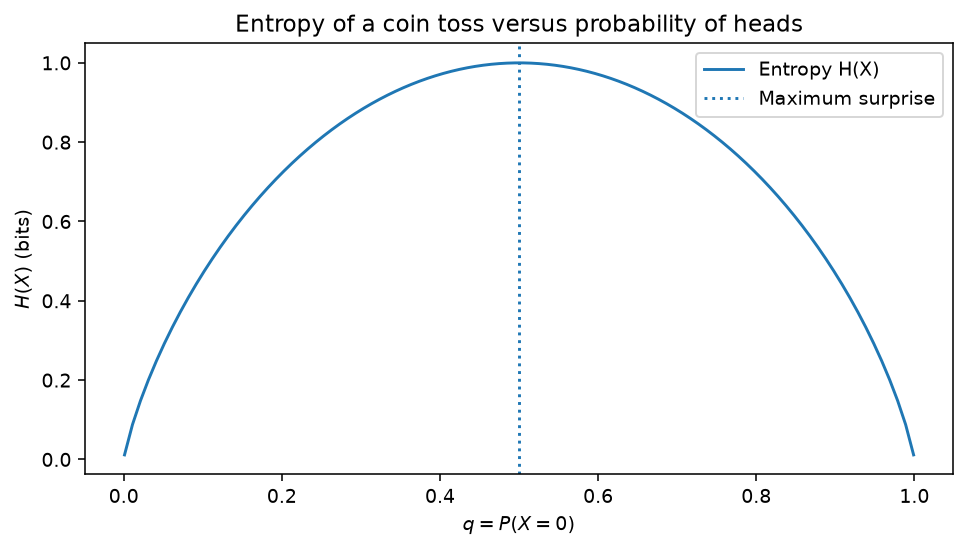

In [23]:
def binary_entropy(q):
    return -q * np.log(q)/np.log(2) - (1-q) * np.log(1-q)/np.log(2)

def plot_binary_entropy():
    x = np.linspace(0.001,0.999,100)
    fig = plt.figure()
    ax = fig.add_subplot(1,1,1)
    ax.plot(x, binary_entropy(x), label="Entropy H(X)")
    ax.axvline(0.5, ls=':', label='Maximum surprise')
    ax.legend()
    ax.set_xlabel('$q=P(X=0)$')
    ax.set_ylabel('$H(X)$ (bits)')
    ax.set_title("Entropy of a coin toss versus probability of heads")
    
plot_binary_entropy()
plt.show()

This corresponds with our intuition -- an unbiased coin toss is the most surprising distribution. Entropy is a critically important concept in **information theory** which relates probability to the problems of communication. We can measure how well Bayesian updating is going by measuring the drop in entropy of the posterior belief; as we add evidence, we should become less surprised about the possible outcomes.


In our letter-based bigram example, we can compute the entropy of each conditional distribution $P(c_i|c_{i-1})$. This will tell us how surprised we will be by the characters that might follow a character $c_{i-1}$.

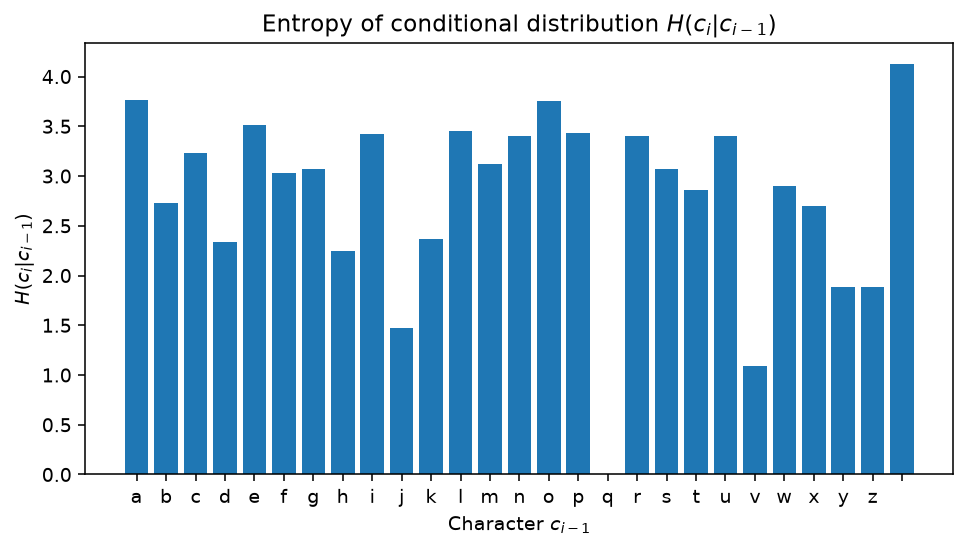

In [21]:
h_meta_conditional = np.sum(-np.log2(meta_conditional+1e-7) * meta_conditional, axis=1)

# plot the entropy of the conditional
fig = plt.figure() 
ax = fig.add_subplot(1,1,1)
plt.bar(np.arange(len(alphabet)), h_meta_conditional)
ax.set_xticks(np.arange(len(alphabet)))
ax.set_xticklabels(alphabet)
ax.set_ylabel("$H(c_i|c_{i-1})$")
ax.set_xlabel("Character $c_{i-1}$")
ax.set_title("Entropy of conditional distribution $H(c_i|c_{i-1})$")
plt.show()


#### Interpreting entropy
We can see that observing a "q" means the next character isn't surprising at all: we know for *sure* that it will be a "u", and thus the entropy is 0.  There is only one configuration of the world for the next character (under this model) if we have just seen a "u".

Likewise, seeing a space character gives us very little information, and the next character could be anything: the character after a space will surprise us -- there are lots of configurations of the world that might follow a space. That surprise is as much surprise as we would get by tossing about 4 coins, or an entropy of about 4 bits.

---

## Resources
### Recommended

* **Probability** by Peter Norvig http://nbviewer.jupyter.org/url/norvig.com/ipython/Probability.ipynb

* **Chapters 2 and 3 of Information Theory, Inference, and Learning Algorithms** by David Mackay (freely available online)
    * http://www.inference.org.uk/mackay/itprnn/ps/22.40.pdf 
    * http://www.inference.org.uk/mackay/itprnn/ps/47.59.pdf
    
---
### Other useful resources
* **Veritasium explains Bayes' Theorem** https://www.youtube.com/watch?v=R13BD8qKeTg    

* **Think Bayes** by Allen Downey  http://greenteapress.com/wp/think-bayes/ (a freely available book on Bayesian probability theory)
    * **Video by same author** https://www.youtube.com/watch?v=TpgiFIGXcT4 
    
* **A collection of very readable articles by Count Bayesie** https://www.countbayesie.com/blog/2016/5/1/a-guide-to-bayesian-statistics 

* **Khan Academy materials on probability** https://www.khanacademy.org/math/statistics-probability/probability-library (more in depth than we cover, but high quality stuff)

## Beyond this course
* [**The Probability and Statistics Cookbook**](http://pages.cs.wisc.edu/~tdw/files/cookbook-en.pdf) which covers most of probability and statistics in 28 incredibly dense pages.

* **Probability Theory: The Logic of Science 1st Edition** *by E. T. Jaynes* (this is an *excellent* but hardcore book; also it is very heavily biased to Bayesian interpretations of probability!)

* **A First Course in Probability ** *by Sheldon Ross* (standard textbook on probability)

* [**Introduction to statistical learning**](http://www-bcf.usc.edu/~gareth/ISL/) (outstanding introduction to statistical learning, including a book, video and course notes)